# Where exactly was pole won? Monza 2025 Qualifying

## Question
Verstappen beat Norris to pole by 0.077 s. Where on the lap did that gap come from?

## Method
- Data: tif1 (TracingInsights cache of F1 timing data), fastest Q3 lap of VER and NOR.
- Telemetry at about 7 to 8 samples per second: speed, throttle, brake (on/off only), distance.
- Time gap computed by interpolating both laps onto 2,000 common distance points.
- Data quality checked: lap distances agree within 0.5 m; each lap has one 0.9 s gap in the data (VER at about 2,820 m, NOR at about 3,480 m), treated as low confidence.

## Result
Verstappen built about 0.07 s on the main straight, then braked **about 10 m later** into the Rettifilo chicane (785 m vs 775 m), carrying more speed into Turn 1 and leading by roughly 0.15 s by Turn 2. Norris won most of it back through Roggia and the Lesmos by braking earlier and getting on the throttle sooner. Verstappen's late braking into Turn 1 was the decisive moment.

**How far to trust it:** the method reproduces the official gap within 0.006 s, but at this sample rate braking points are only accurate to roughly 10 m, and brake data is on/off, so braking *pressure* can't be compared.

## Next time
- Compare 3 laps each, not 1, to separate driving from lap to lap noise.
- Add tyre age and track evolution between the two laps.
- Cross check the data gaps against a second source such as FastF1 when access is available.

In [ ]:
import tif1

session = tif1.get_session(2025, 'Italian Grand Prix', 'Qualifying')

ver_lap = session.laps.pick_drivers('VER').pick_fastest()
nor_lap = session.laps.pick_drivers('NOR').pick_fastest()

print(ver_lap['LapTime'])
print(nor_lap['LapTime'])

ver_tel = ver_lap.get_car_data().add_distance()
nor_tel = nor_lap.get_car_data().add_distance()

ver_tel.head()

0 days 00:01:18.792000
0 days 00:01:18.869000


,Time,RPM,Speed,nGear,Throttle,Brake,DRS,Distance,RelativeDistance,DriverAhead,DistanceToDriverAhead,AccelerationX,AccelerationY,AccelerationZ,X,Y,Z,Driver,LapNumber
0,0 days 00:00:00,11381.404580,321.645455,8,100.0,False,0,0.018979,0.000003,NaN,802.070000,0.841750,-0.329904,-3.730813,-1373.650597,-676.336105,1871.232164,VER,17
1,0 days 00:00:00.287000,11459.024983,322.950000,8,100.0,False,0,25.822479,0.004472,NaN,802.070000,2.483654,-0.395070,0.070925,-1346.000000,-352.000000,1873.000000,VER,17
2,0 days 00:00:00.298000,11462.000000,323.000000,8,100.0,False,1,26.816111,0.004644,NaN,802.070000,3.360656,-0.326455,2.844323,-1345.304479,-344.042629,1873.058849,VER,17
3,0 days 00:00:00.459000,11415.000000,326.000000,8,100.0,False,1,41.395556,0.007169,4,802.070000,3.455617,-0.223683,1.694418,-1337.809285,-260.635587,1873.822443,VER,17
4,0 days 00:00:00.547000,11446.376061,326.490251,8,100.0,False,1,49.387330,0.008553,4,797.767775,2.329550,-0.140023,0.182752,-1333.000000,-207.000000,1874.000000,VER,17


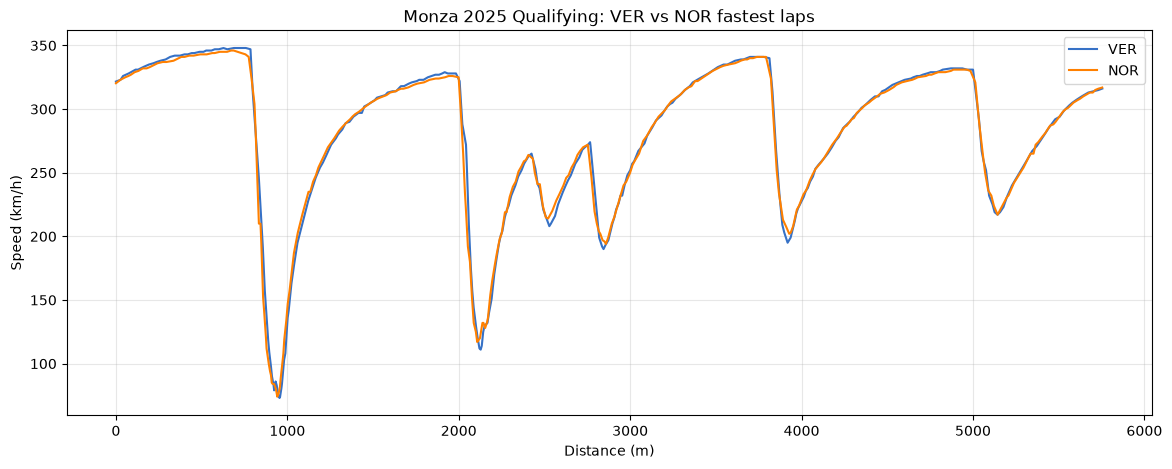

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(ver_tel['Distance'], ver_tel['Speed'], label='VER', color='#3671C6')
ax.plot(nor_tel['Distance'], nor_tel['Speed'], label='NOR', color='#FF8000')

ax.set_xlabel('Distance (m)')
ax.set_ylabel('Speed (km/h)')
ax.set_title('Monza 2025 Qualifying: VER vs NOR fastest laps')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

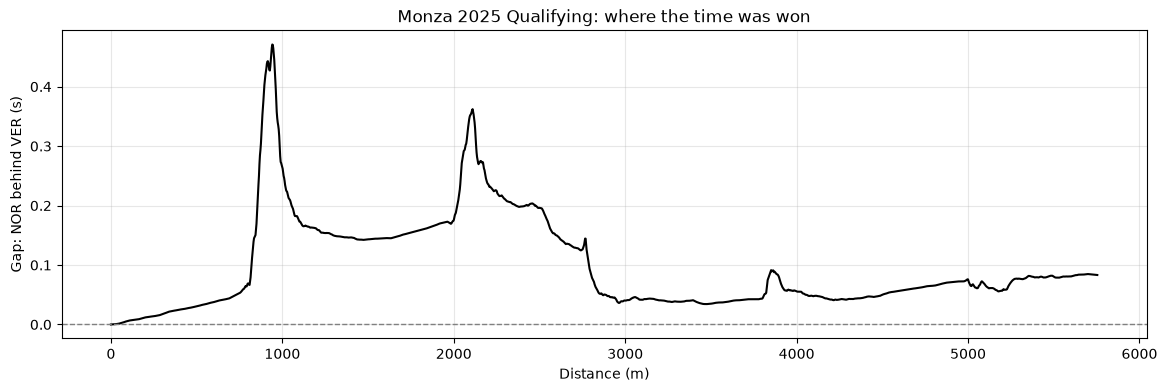

Gap at the finish line: 0.083 s


In [ ]:
import numpy as np

lap_length = min(ver_tel['Distance'].max(), nor_tel['Distance'].max())
dist = np.linspace(0, lap_length, 2000)

ver_time = np.interp(dist, ver_tel['Distance'], ver_tel['Time'].dt.total_seconds())
nor_time = np.interp(dist, nor_tel['Distance'], nor_tel['Time'].dt.total_seconds())

delta = nor_time - ver_time

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dist, delta, color='black')
ax.axhline(0, color='grey', linestyle='--', linewidth=1)

ax.set_xlabel('Distance (m)')
ax.set_ylabel('Gap: NOR behind VER (s)')
ax.set_title('Monza 2025 Qualifying: where the time was won')
ax.grid(alpha=0.3)

plt.show()

print('Gap at the finish line:', round(delta[-1], 3), 's')

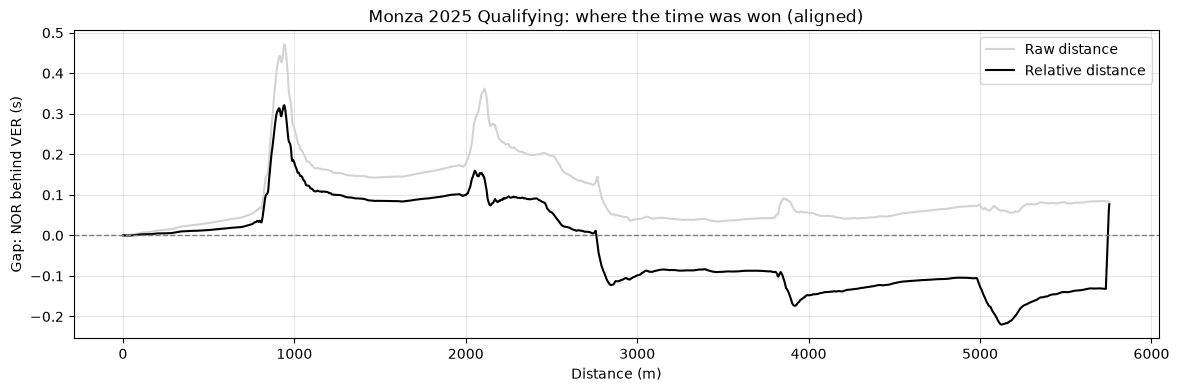

Gap at the finish line: 0.077 s


In [ ]:
rel = np.linspace(0, 1, 2000)

ver_time_rel = np.interp(rel, ver_tel['RelativeDistance'], ver_tel['Time'].dt.total_seconds())
nor_time_rel = np.interp(rel, nor_tel['RelativeDistance'], nor_tel['Time'].dt.total_seconds())

delta_rel = nor_time_rel - ver_time_rel
dist_rel = rel * lap_length

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dist, delta, color='lightgrey', label='Raw distance')
ax.plot(dist_rel, delta_rel, color='black', label='Relative distance')
ax.axhline(0, color='grey', linestyle='--', linewidth=1)

ax.set_xlabel('Distance (m)')
ax.set_ylabel('Gap: NOR behind VER (s)')
ax.set_title('Monza 2025 Qualifying: where the time was won (aligned)')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print('Gap at the finish line:', round(delta_rel[-1], 3), 's')

In [ ]:
for name, tel in [('VER', ver_tel), ('NOR', nor_tel)]:
    t = tel['Time'].dt.total_seconds()
    print(name)
    print('  samples:', len(tel))
    print('  last time:', round(t.max(), 3), 's')
    print('  max distance:', round(tel['Distance'].max(), 1), 'm')
    print('  RelativeDistance from', round(tel['RelativeDistance'].min(), 4), 'to', round(tel['RelativeDistance'].max(), 4))
    print('  Distance always increasing?', tel['Distance'].is_monotonic_increasing)
    print('  RelativeDistance always increasing?', tel['RelativeDistance'].is_monotonic_increasing)
    gaps = t.diff()
    i = gaps.idxmax()
    print('  biggest gap between samples:', round(gaps.max(), 3), 's at', round(tel.loc[i, 'Distance'], 1), 'm')

VER
  samples: 587
  last time: 78.792 s
  max distance: 5754.4 m
  RelativeDistance from 0.0 to 0.9965
  Distance always increasing? True
  RelativeDistance always increasing? True
  biggest gap between samples: 0.901 s at 2817.6 m
NOR
  samples: 592
  last time: 78.869 s
  max distance: 5753.9 m
  RelativeDistance from 0.0 to 0.9997
  Distance always increasing? True
  RelativeDistance always increasing? True
  biggest gap between samples: 0.901 s at 3478.5 m


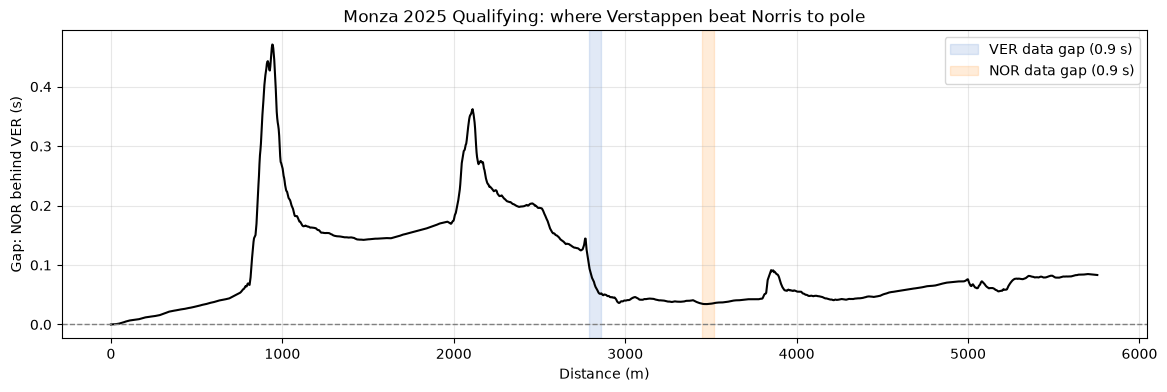

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(dist, delta, color='black')
ax.axhline(0, color='grey', linestyle='--', linewidth=1)

ax.axvspan(2790, 2860, color='#3671C6', alpha=0.15, label='VER data gap (0.9 s)')
ax.axvspan(3450, 3520, color='#FF8000', alpha=0.15, label='NOR data gap (0.9 s)')

ax.set_xlabel('Distance (m)')
ax.set_ylabel('Gap: NOR behind VER (s)')
ax.set_title('Monza 2025 Qualifying: where Verstappen beat Norris to pole')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [ ]:
def plot_corner(start, end, title):
    v = ver_tel[(ver_tel['Distance'] >= start) & (ver_tel['Distance'] <= end)]
    n = nor_tel[(nor_tel['Distance'] >= start) & (nor_tel['Distance'] <= end)]

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    for tel, name, color in [(v, 'VER', '#3671C6'), (n, 'NOR', '#FF8000')]:
        axes[0].plot(tel['Distance'], tel['Speed'], color=color, label=name)
        axes[1].plot(tel['Distance'], tel['Throttle'], color=color)
        axes[2].step(tel['Distance'], tel['Brake'].astype(int), color=color, where='post')

        braking = tel[tel['Brake']]
        if len(braking) > 0:
            print(name, 'first on the brakes at', round(braking['Distance'].iloc[0]), 'm')

    axes[0].set_ylabel('Speed (km/h)')
    axes[1].set_ylabel('Throttle (%)')
    axes[2].set_ylabel('Brake (on/off)')
    axes[2].set_xlabel('Distance (m)')
    axes[0].set_title(title)
    axes[0].legend()
    for ax in axes:
        ax.grid(alpha=0.3)

    plt.show()

VER first on the brakes at 785 m
NOR first on the brakes at 775 m


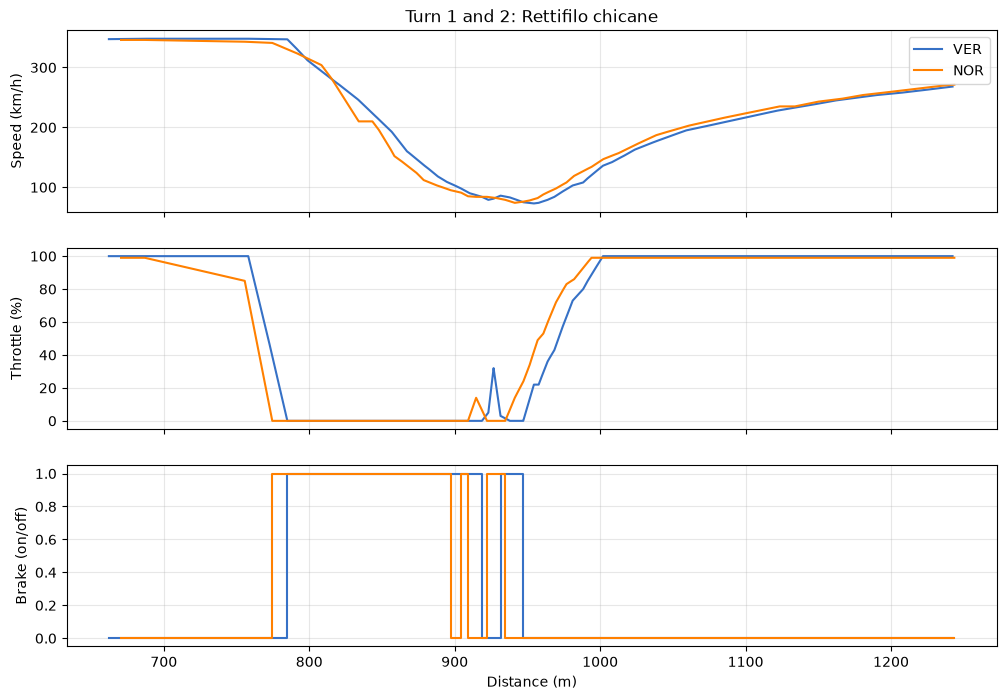

In [ ]:
plot_corner(650, 1250, 'Turn 1 and 2: Rettifilo chicane')

VER first on the brakes at 2021 m
NOR first on the brakes at 1999 m


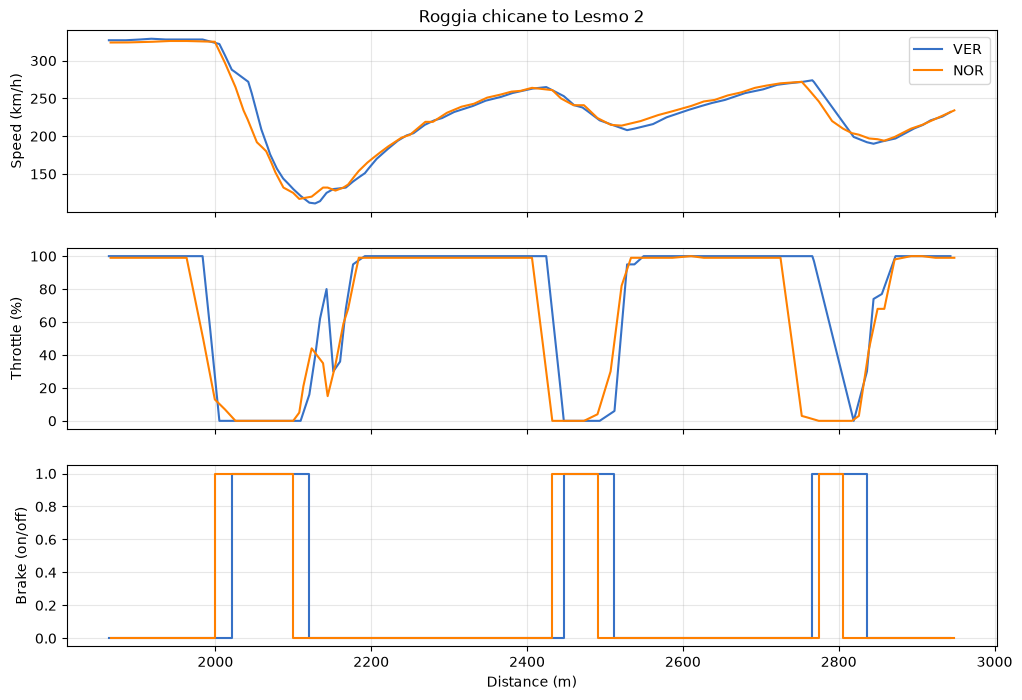

In [ ]:
plot_corner(1850, 2950, 'Roggia chicane to Lesmo 2')

In [1]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Segoe UI', 'Arial', 'DejaVu Sans'],
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'legend.frameon': False,
    'figure.dpi': 110,
})

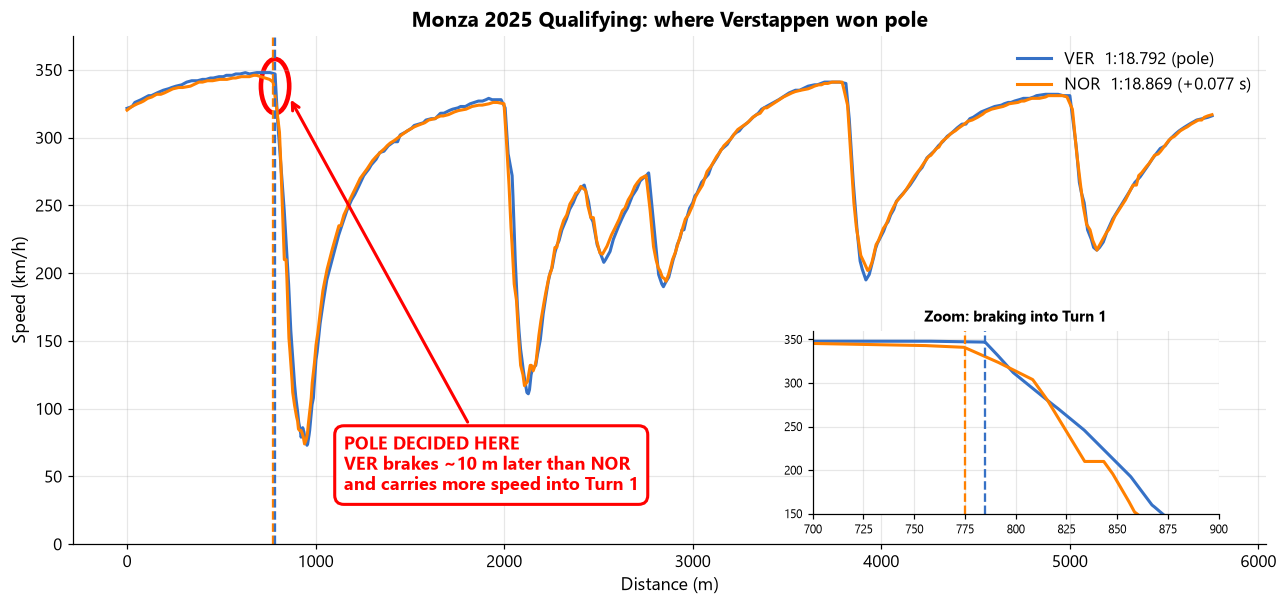

In [2]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(ver_tel['Distance'], ver_tel['Speed'], label='VER  1:18.792 (pole)', color='#3671C6', linewidth=2)
ax.plot(nor_tel['Distance'], nor_tel['Speed'], label='NOR  1:18.869 (+0.077 s)', color='#FF8000', linewidth=2)

# brake points as dashed vertical lines
ax.axvline(775, color='#FF8000', linestyle='--', linewidth=1.5)
ax.axvline(785, color='#3671C6', linestyle='--', linewidth=1.5)

# tight red circle on the braking point only
ax.add_patch(Ellipse((785, 338), width=150, height=40, fill=False, color='red', linewidth=3))

# bold callout box
ax.annotate('POLE DECIDED HERE\nVER brakes ~10 m later than NOR\nand carries more speed into Turn 1',
            xy=(860, 330), xytext=(1150, 40),
            fontsize=12, fontweight='bold', color='red',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='red', linewidth=2),
            arrowprops=dict(arrowstyle='->', color='red', linewidth=2))

# zoomed inset of the braking zone
axins = ax.inset_axes([0.62, 0.06, 0.34, 0.36])
axins.plot(ver_tel['Distance'], ver_tel['Speed'], color='#3671C6', linewidth=2)
axins.plot(nor_tel['Distance'], nor_tel['Speed'], color='#FF8000', linewidth=2)
axins.axvline(775, color='#FF8000', linestyle='--', linewidth=1.5)
axins.axvline(785, color='#3671C6', linestyle='--', linewidth=1.5)
axins.set_xlim(700, 900)
axins.set_ylim(150, 360)
axins.set_title('Zoom: braking into Turn 1', fontsize=10)
axins.tick_params(labelsize=8)
axins.grid(alpha=0.3)

ax.set_ylim(0, 375)
ax.set_xlabel('Distance (m)')
ax.set_ylabel('Speed (km/h)')
ax.set_title('Monza 2025 Qualifying: where Verstappen won pole', fontsize=14, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)

plt.savefig('speed_trace_turn1.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# The ghost car replay is built by make_animation.py, so there is only one copy of its code.
%run ../make_animation.py